# Quantitative Risk & Portfolio Optimization

Historical cross-asset risk analysis, statistical inference, and constrained mean-variance portfolio optimization using Python.

**Data:** daily closing prices, January 2020–September 29, 2026. **Sample convention:** shared trading dates, 252 trading days annually. **Risk-free rate:** 4%.

Run the notebook from the repository root with the dataset at `data/daily_prices.csv`.


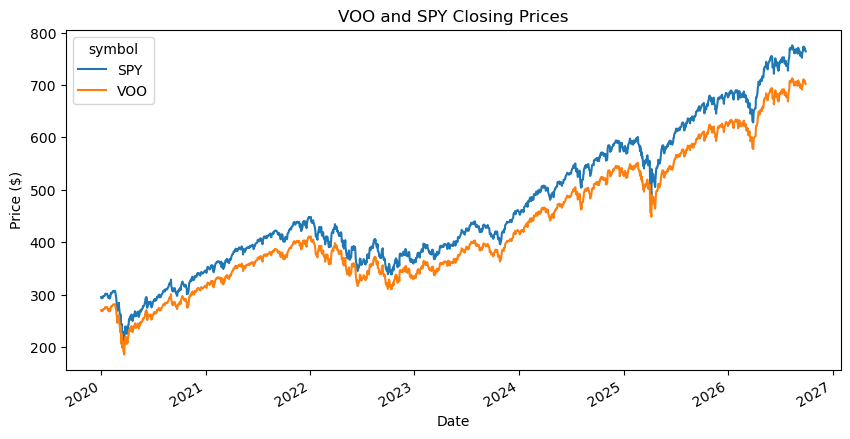

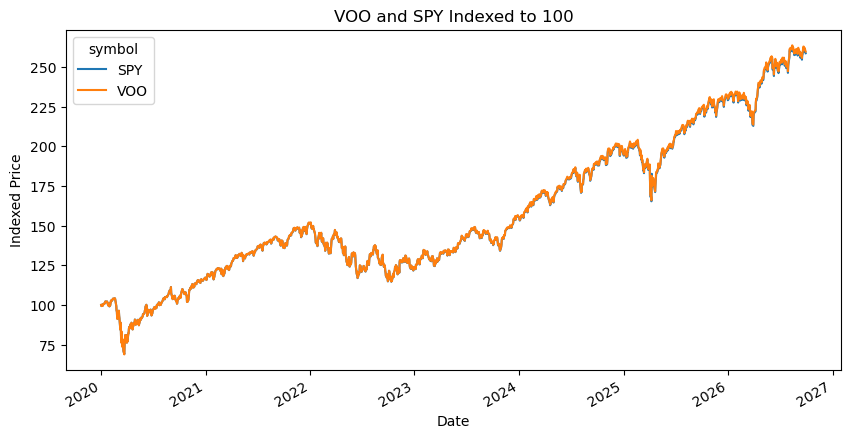

In [34]:
import pandas as pd
import matplotlib.pyplot as plt

# reading the data
columns = ['symbol', 'date', 'open', 'high', 'low', 'close',
           'volume', 'adjustment', 'source', 'retrieved']

df = pd.read_csv('data/daily_prices.csv', names=columns)
df['date'] = pd.to_datetime(df['date'])

# selecting VOO and SPY for the specific period
df = df[(df['symbol'].isin(['VOO', 'SPY'])) &
        (df['date'] >= '2020-01-01') &
        (df['date'] <= '2026-09-29')]

prices = df.pivot_table(index='date', columns='symbol', values='close')
prices = prices.dropna().sort_index()

# graph 1: Actual closing prices
prices.plot(figsize=(10, 5))
plt.title('VOO and SPY Closing Prices')
plt.xlabel('Date')
plt.ylabel('Price ($)')
plt.savefig('figures/VOO_SPY_Closing_Prices.png', dpi=300, bbox_inches='tight')
plt.show()

# graph 2: Both starting at 100
indexed = prices / prices.iloc[0] * 100

indexed.plot(figsize=(10, 5))
plt.title('VOO and SPY Indexed to 100')
plt.xlabel('Date')
plt.ylabel('Indexed Price')
plt.savefig('figures/VOO_SPY_Indexed.png', dpi=300, bbox_inches='tight')
plt.show()


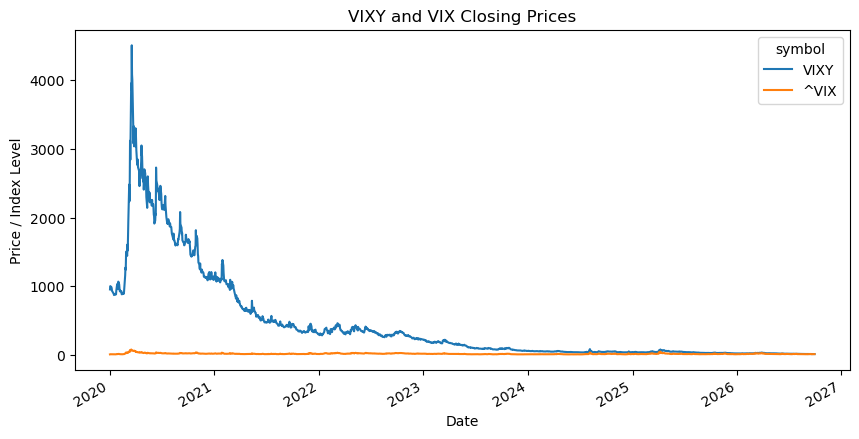

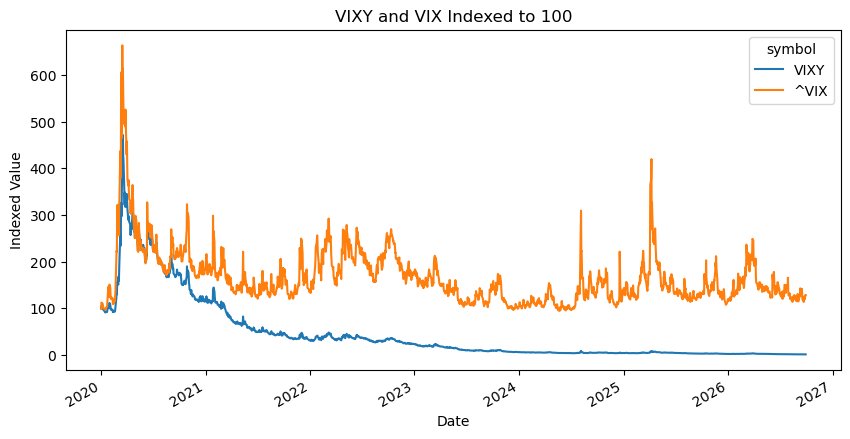

In [35]:
### Market volatility: VIXY vs. VIX

# getting VIXY and VIX prices
volatility = pd.read_csv('data/daily_prices.csv', names=columns)
volatility['date'] = pd.to_datetime(volatility['date'])

volatility = volatility[
    (volatility['symbol'].isin(['VIXY', '^VIX'])) &
    (volatility['date'] >= '2020-01-01') &
    (volatility['date'] <= '2026-09-29')
]

prices_vix = volatility.pivot_table(index='date', columns='symbol', values='close')
prices_vix = prices_vix.dropna().sort_index()

# the actual closing prices
prices_vix.plot(figsize=(10, 5))
plt.title('VIXY and VIX Closing Prices')
plt.xlabel('Date')
plt.ylabel('Price / Index Level')
plt.savefig('figures/VIXY_VIX_Prices.png', dpi=300, bbox_inches='tight')
plt.show()

# indexed to 100
indexed_vix = prices_vix / prices_vix.iloc[0] * 100

indexed_vix.plot(figsize=(10, 5))
plt.title('VIXY and VIX Indexed to 100')
plt.xlabel('Date')
plt.ylabel('Indexed Value')
plt.savefig('figures/VIXY_VIX_Indexed.png', dpi=300, bbox_inches='tight')
plt.show()


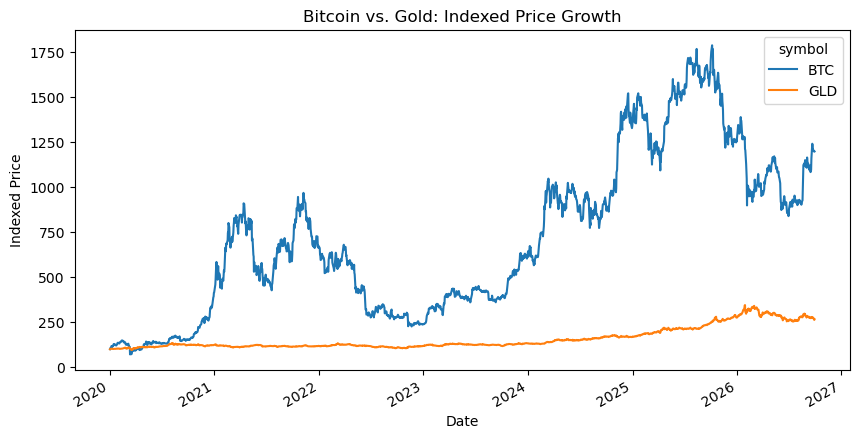

In [36]:
### bitcoin vs. gold: growth and price fluctuations

# comparing btc and gold
assets = pd.read_csv('data/daily_prices.csv', names=columns)
assets['date'] = pd.to_datetime(assets['date'])

assets = assets[
    (assets['symbol'].isin(['BTC', 'GLD'])) &
    (assets['date'] >= '2020-01-01') &
    (assets['date'] <= '2026-09-29')
]

btc_gold = assets.pivot_table(index='date', columns='symbol', values='close')
btc_gold = btc_gold.dropna().sort_index()

# growth from the same starting point
growth = btc_gold / btc_gold.iloc[0] * 100

growth.plot(figsize=(10, 5))
plt.title('Bitcoin vs. Gold: Indexed Price Growth')
plt.xlabel('Date')
plt.ylabel('Indexed Price')
plt.savefig('figures/BTC_GLD_Growth.png', dpi=300, bbox_inches='tight')
plt.show()


## Risk and return analysis

I calculate daily returns and use them to estimate the average return, variance, and volatility of 8 assets. These measures help us compare their performance and risk.

### Math Notes

daily return measures the % change in price from 1 trading day to the next.

mean return tells us the average return across the sample.

variance measures how much returns fluctuate around their average. I subtract the mean from each return, square the differences, add them together, and divide by n - 1.

volatility is the square root of variance. It measures the size of the typical fluctuations in returns.


In [38]:
# loading the 8 assets
stocks = ['VOO', 'QQQ', 'VIXY', 'TSLA', 'BRK-B', 'GLD', 'BTC', 'ETH']

data = pd.read_csv('data/daily_prices.csv', names=columns)
data['date'] = pd.to_datetime(data['date'])

data = data[
    (data['symbol'].isin(stocks)) &
    (data['date'] >= '2020-01-01') &
    (data['date'] <= '2026-09-29')
]

# dates matching and calculating daily returns
prices = data.pivot_table(index='date', columns='symbol', values='close')
prices = prices[stocks].dropna().sort_index()

returns = prices.pct_change().dropna()

# daily/annualized estimates
daily_mean = returns.mean()
daily_variance = returns.var()

annual_return = daily_mean * 252
annual_variance = daily_variance * 252
annual_volatility = annual_variance ** 0.5

# results
results = pd.DataFrame({
    'Daily Mean': daily_mean,
    'Daily Variance': daily_variance,
    'Annual Return': annual_return,
    'Annual Variance': annual_variance,
    'Annual Volatility': annual_volatility
})

print(results.round(4))


        Daily Mean  Daily Variance  Annual Return  Annual Variance  \
symbol                                                               
VOO         0.0006          0.0002         0.1625           0.0406   
QQQ         0.0009          0.0002         0.2195           0.0617   
VIXY       -0.0013          0.0023        -0.3306           0.5697   
TSLA        0.0023          0.0017         0.5818           0.4178   
BRK-B       0.0006          0.0002         0.1387           0.0427   
GLD         0.0006          0.0001         0.1629           0.0344   
BTC         0.0022          0.0014         0.5520           0.3584   
ETH         0.0031          0.0026         0.7832           0.6537   

        Annual Volatility  
symbol                     
VOO                0.2015  
QQQ                0.2484  
VIXY               0.7548  
TSLA               0.6464  
BRK-B              0.2066  
GLD                0.1856  
BTC                0.5987  
ETH                0.8085  


One interesting result is that VIXY has a negative annualized return but very high variance, while ETH has both the highest estimated return and the highest variance. This shows that having high risk doesn't necessarily mean an investment will have high returns. Variance measures how much daily returns move away from their average, whether those movements are + or - . Large fluctuations can produce high variance even when the average return is negative.


### Covariance and Correlation Analysis

Covariance measures how 2 assets' returns move together, while correlation measures the strength and direction of their relationship. I use these measures to examine how closely the 8 assets are related and what this might mean for diversification.

In [41]:
# covariance and correlation
covariance = returns.cov()
correlation = returns.corr()

print("Covariance Matrix")
print(covariance.round(5))

print("\nCorrelation Matrix")
print(correlation.round(3))


Covariance Matrix
symbol      VOO      QQQ     VIXY     TSLA    BRK-B      GLD      BTC      ETH
symbol                                                                        
VOO     0.00016  0.00019 -0.00045  0.00027  0.00012  0.00002  0.00018  0.00025
QQQ     0.00019  0.00024 -0.00053  0.00039  0.00011  0.00003  0.00023  0.00031
VIXY   -0.00045 -0.00053  0.00226 -0.00087 -0.00032 -0.00005 -0.00061 -0.00084
TSLA    0.00027  0.00039 -0.00087  0.00166  0.00014  0.00004  0.00048  0.00065
BRK-B   0.00012  0.00011 -0.00032  0.00014  0.00017  0.00000  0.00011  0.00015
GLD     0.00002  0.00003 -0.00005  0.00004  0.00000  0.00014  0.00006  0.00008
BTC     0.00018  0.00023 -0.00061  0.00048  0.00011  0.00006  0.00142  0.00157
ETH     0.00025  0.00031 -0.00084  0.00065  0.00015  0.00008  0.00157  0.00259

Correlation Matrix
symbol    VOO    QQQ   VIXY   TSLA  BRK-B    GLD    BTC    ETH
symbol                                                        
VOO     1.000  0.932 -0.754  0.529  0.717  0.1

One thing I noticed is a "-" correlation doesn't necessarily mean an asset is a good investment. For example, VIXY has a strong "-" correlation with VOO, which suggests it could provide some diversification benefits. However, VIXY also has a negative estimated annualized return and high volatility. This shows correlation alone may not enough when evaluating assets for a portfolio

### Comparing annualized volatility across assets

I compare the annualized volatility of 8 assets to see how their historical risk levels differ. This helps show why investors should consider risk alongside expected returns.

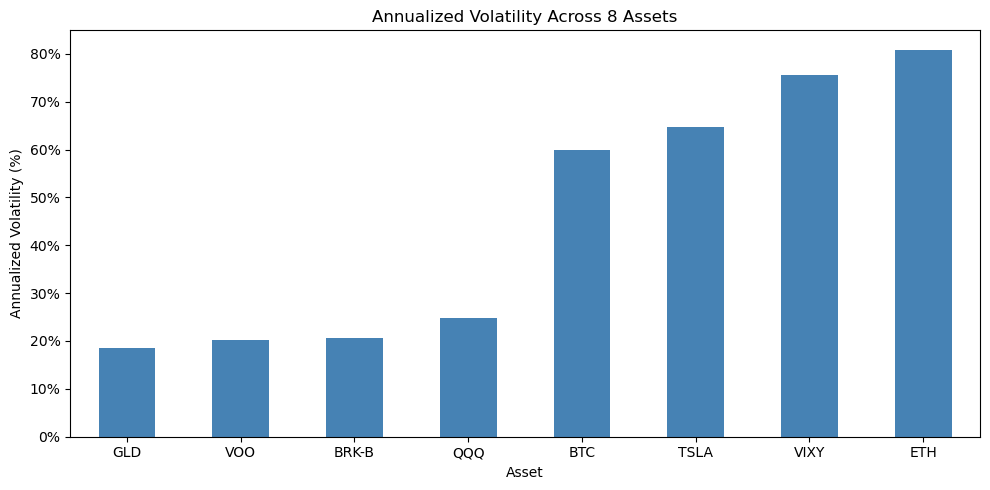

In [44]:
# compared annualized volat. across assets
volatility = annual_volatility.sort_values()

volatility.plot(kind='bar', figsize=(10, 5), color='steelblue')

plt.title('Annualized Volatility Across 8 Assets')
plt.xlabel('Asset')
plt.ylabel('Annualized Volatility (%)')
plt.xticks(rotation=0)

plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, pos: f'{x * 100:.0f}%')
)

plt.tight_layout()
plt.savefig('figures/Annual_Volatility.png', dpi=300, bbox_inches='tight')
plt.show()


**Volatility:** the square root of variance. It measures how much returns fluctuate around their average.

To calculate annualized volatility, I multiply daily variance by 252 (the assumed number of trading days in a year) and then take the square root.

$$
\sigma_{\text{annual}} = \sqrt{252 \times s_{\text{daily}}^2}
$$

For example, ETH's daily variance is approximately 0.002594. Therefore:

$$
\sqrt{252 \times 0.002594}
\approx \sqrt{0.6537}
\approx 0.8085 = 80.85\%
$$

This also explains taking the square root of annualized variance gives the same result: annualized variance is simply daily variance multiplied by 252.


## Statistical Inference: Testing VOO's Annualized Return

using a two-sided t-test at the 1% significance level to examine whether VOO's mean annualized log return differs from 10%.

In [47]:
import numpy as np
from scipy import stats

# VOO's daily log returns
voo = np.log(prices['VOO'] / prices['VOO'].shift(1)).dropna()

# sample statistics
n = len(voo)
mean = voo.mean()
std = voo.std()

# testing the 10% annualized return claim
claimed_mean = 0.10 / 252
t_stat = (mean - claimed_mean) / (std / np.sqrt(n))

# critical values and p-value
critical = stats.t.ppf(0.995, df=n-1)
p_value = 2 * stats.t.sf(abs(t_stat), df=n-1)

print("Observations:", n)
print("Mean log return:", round(mean, 6))
print("Standard deviation:", round(std, 6))
print("T-statistic:", round(t_stat, 4))
print("Critical values:", round(-critical, 4), round(critical, 4))
print("P-value:", round(p_value, 6))


Observations: 1693
Mean log return: 0.000564
Standard deviation: 0.012729
T-statistic: 0.54
Critical values: -2.5787 2.5787
P-value: 0.589297


### Interpretation

The t-statistic measures how far the estimated mean is from the claimed mean, in standard errors.

The critical values define the rejection region. Since the t-statistic (0.54) is between -2.5787 and 2.5787, I fail to reject the null hypothesis.

The p-value (0.5893) is greater than 0.01, so there is not enough statistical evidence to conclude that VOO's annualized mean log return differs from 10%.

Failing to reject the null hypothesis doesn't mean the claim is proven true.


## Portfolio Optimization

### Global Minimum Variance Portfolio

I want to find the combination of 8 assets that gives the lowest possible portfolio variance. The weights must add up to 1 (100%), but "-" weights are allowed because short selling is permitted.

I use the annualized covariance matrix to find the optimal weights, then calculate the portfolio's expected return, volatility, and Sharpe ratio.


In [50]:
# annualized returns and covariance
mu = returns.mean() * 252
sigma = returns.cov() * 252

# minimum variance portfolio weights
ones = np.ones(len(mu))
inverse = np.linalg.inv(sigma.values)

weights = inverse @ ones / (ones @ inverse @ ones)

# calculating portfolio return, volatility, and Sharpe ratio
portfolio_return = weights @ mu
portfolio_variance = weights @ sigma @ weights
portfolio_volatility = np.sqrt(portfolio_variance)
sharpe = (portfolio_return - 0.04) / portfolio_volatility

print("Weights")
print(pd.Series(weights, index=mu.index).round(4))

print("\nExpected Annual Return:", round(portfolio_return, 4))
print("Annual Volatility:", round(portfolio_volatility, 4))
print("Sharpe Ratio:", round(sharpe, 4))
print("Sum of Weights:", round(sum(weights), 4))


Weights
symbol
VOO      0.5741
QQQ     -0.0587
VIXY     0.1378
TSLA    -0.0017
BRK-B    0.1108
GLD      0.2339
BTC      0.0164
ETH     -0.0127
dtype: float64

Expected Annual Return: 0.0865
Annual Volatility: 0.0962
Sharpe Ratio: 0.4828
Sum of Weights: 1.0


### Interpretation

The min. variance portfolio has an estimated annual return of 8.65%, annualized volatility of 9.62%, and a Sharpe ratio of 0.4828.

VOO has the largest weight (57.41%), followed by GLD (23.39%). Interestingly, VIXY receives a positive weight (13.78%) despite its negative expected return. This is likely because its negative correlation with stock market assets helps reduce overall portfolio risk.

Some weights are negative because short selling is allowed. An asset doesn't necessarily have to be a bad investment to receive a negative weight. It considers how each asset moves in relation to the others, not just its individual performance.

**Sharpe Ratio:** The Sharpe ratio measures the expected return above the risk-free rate for each unit of volatility. Using the 4% annual risk-free rate:

$$
\text{Sharpe Ratio} = \frac{\text{Expected Return} - \text{Risk-Free Rate}}{\text{Volatility}}
$$

For this portfolio:

$$
\frac{0.0865 - 0.04}{0.0962} \approx 0.483
$$

The result is approximately 0.4828 using the unrounded values from Python. This means the portfolio provides about 0.48 units of expected excess return per unit of volatility.

The weights add up to 100%, and the goal of this portfolio is to minimize risk rather than maximize returns.


### Target Return Portfolios and Efficient Frontier

I calculate the minimum variance portfolios for annualized expected returns of 10% and 15%. The weights must add up to 100%, and short selling is allowed.

I then use the portfolio variance equation to plot the efficient frontier and compare the target portfolios with the global minimum variance portfolio.


In [56]:
# constants for the efficient frontier
A = ones @ inverse @ ones
B = ones @ inverse @ mu
C = mu @ inverse @ mu
D = A * C - B**2

# portfolio weights for a target return
def target_portfolio(target):
    return inverse @ ((C - B * target) * ones +
                      (A * target - B) * mu) / D

for target in [0.10, 0.15]:
    w = target_portfolio(target)
    risk = np.sqrt(w @ sigma @ w)
    sharpe = (w @ mu - 0.04) / risk

    print(f"\nTarget Return: {target:.0%}")
    print(pd.Series(w, index=mu.index).round(4))
    print("Expected Return:", round(w @ mu, 4))
    print("Volatility:", round(risk, 4))
    print("Sharpe Ratio:", round(sharpe, 4))
    print("Sum of Weights:", round(sum(w), 4))



Target Return: 10%
symbol
VOO      0.4645
QQQ     -0.0067
VIXY     0.1318
TSLA     0.0059
BRK-B    0.1412
GLD      0.2507
BTC      0.0180
ETH     -0.0054
dtype: float64
Expected Return: 0.1
Volatility: 0.0969
Sharpe Ratio: 0.6193
Sum of Weights: 1.0

Target Return: 15%
symbol
VOO      0.0600
QQQ      0.1851
VIXY     0.1096
TSLA     0.0339
BRK-B    0.2533
GLD      0.3127
BTC      0.0237
ETH      0.0217
dtype: float64
Expected Return: 0.15
Volatility: 0.1099
Sharpe Ratio: 1.001
Sum of Weights: 1.0


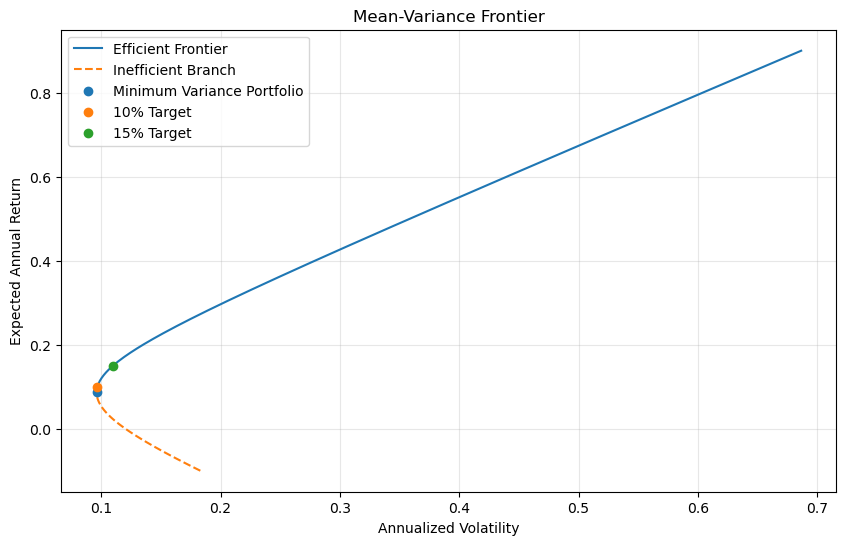

In [58]:
# the minimum variance frontier
targets = np.linspace(-0.10, 0.90, 300)
variances = (A * targets**2 - 2 * B * targets + C) / D
risks = np.sqrt(variances)

gmv_return = portfolio_return

# plotting the efficient and inefficient branches
plt.figure(figsize=(10, 6))

plt.plot(risks[targets >= gmv_return],
         targets[targets >= gmv_return],
         label='Efficient Frontier')

plt.plot(risks[targets < gmv_return],
         targets[targets < gmv_return],
         '--', label='Inefficient Branch')

plt.scatter(portfolio_volatility, gmv_return,
            label='Minimum Variance Portfolio', zorder=3)

for target in [0.10, 0.15]:
    w = target_portfolio(target)
    risk = np.sqrt(w @ sigma @ w)
    plt.scatter(risk, target, label=f'{target:.0%} Target', zorder=3)

plt.xlabel('Annualized Volatility')
plt.ylabel('Expected Annual Return')
plt.title('Mean-Variance Frontier')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig('figures/Efficient_Frontier.png', dpi=300, bbox_inches='tight')
plt.show()


### Interpretation

The 10% target portfolio has an annualized volatility of 9.69% and a Sharpe ratio of 0.6193, while the 15% target portfolio has a volatility of 10.99% and a Sharpe ratio of 1.0010.

Both portfolios lie on the efficient branch because their expected returns are above the global minimum variance portfolio's return of 8.65%.

The graph shows that achieving a higher expected return requires accepting more risk along the efficient frontier. The lower branch is inefficient because another portfolio can offer a higher expected return for the same volatility.

The portfolio weights also change as the target return increases, showing how the optimization balances expected returns with risk and the relationships between assets.


### Deriving Minimum Variance Frontier

The goal is to find the portfolio with the lowest variance for a given expected return. The weights must add up to 1, and the portfolio must achieve the target return, m.

**Step 1:**

We minimize portfolio variance:

$$
\min_w \; w^T\Sigma w
$$

subject to:

$$
\mathbf{1}^Tw=1, \qquad w^T\mu=m
$$

Here, w represents the portfolio weights, Σ is the annualized covariance matrix, μ is the vector of expected annual returns, and m is the target return.

**Step 2: Lagrangian**

Since there are 2 constraints, I introduce two Lagrange multipliers:

$$
L=w^T\Sigma w-\lambda(\mathbf{1}^Tw-1)-\gamma(w^T\mu-m)
$$

Differentiating with respect to w gives:

$$
2\Sigma w-\lambda\mathbf{1}-\gamma\mu=0
$$

Rearranging:

$$
w=\frac{1}{2}\Sigma^{-1}(\lambda\mathbf{1}+\gamma\mu)
$$

Letting a = λ/2 and b = γ/2 simplifies this to:

$$
w=\Sigma^{-1}(a\mathbf{1}+b\mu)
$$

**Step 3: Apply 2 constraints**

Using the condition that the weights sum to 1:

$$
\mathbf{1}^T\Sigma^{-1}(a\mathbf{1}+b\mu)=1
$$

Using the definitions:

$$
A=\mathbf{1}^T\Sigma^{-1}\mathbf{1},
\qquad B=\mathbf{1}^T\Sigma^{-1}\mu
$$

We get:

$$
Aa+Bb=1
$$

Similarly, applying the target-return constraint:

$$
\mu^T\Sigma^{-1}(a\mathbf{1}+b\mu)=m
$$

With:

$$
C=\mu^T\Sigma^{-1}\mu
$$

This becomes:

$$
Ba+Cb=m
$$

**Step 4: Solve for a and b**

We now have two equations:

$$
Aa+Bb=1
$$

$$
Ba+Cb=m
$$

Solving these equations and defining D = AC - B² gives:

$$
a=\frac{C-Bm}{D},
\qquad
b=\frac{Am-B}{D}
$$

**Step 5: frontier equation**

Portfolio variance is:

$$
\sigma^2(m)=w^T\Sigma w
$$

Since:

$$
\Sigma w=a\mathbf{1}+b\mu
$$

We can write:

$$
\sigma^2(m)=w^T(a\mathbf{1}+b\mu)
$$

Using the two constraints, this simplifies to:

$$
\sigma^2(m)=a+bm
$$

Substituting the expressions for a and b:

$$
\sigma^2(m)=\frac{C-Bm}{D}+m\frac{Am-B}{D}
$$

Combining and simplifying:

$$
\boxed{\sigma^2(m)=\frac{Am^2-2Bm+C}{D}}
$$

This is the minimum variance frontier equation. It gives the lowest possible portfolio variance for each target expected return, assuming short selling is allowed and the covariance matrix is invertible.


### Tangency Portfolio and Capital Market Line

I use a 4% annual risk-free rate to find the portfolio that maximizes the Sharpe ratio. Unlike the minimum variance portfolio, the goal here is to find the greatest expected excess return for each unit of risk.

I also calculate how much to invest in the tangency portfolio and the risk-free asset to achieve overall expected returns of 10% and 15%.


In [65]:
# tangency portfolio
risk_free = 0.04

excess_returns = mu - risk_free
tangency = inverse @ excess_returns
tangency = tangency / sum(tangency)

# portfolio results
t_return = tangency @ mu
t_volatility = np.sqrt(tangency @ sigma @ tangency)
t_sharpe = (t_return - risk_free) / t_volatility

print("Tangency Portfolio Weights")
print(pd.Series(tangency, index=mu.index).round(4))

print("\nExpected Return:", round(t_return, 4))
print("Annual Volatility:", round(t_volatility, 4))
print("Sharpe Ratio:", round(t_sharpe, 4))
print("Sum of Weights:", round(sum(tangency), 4))


Tangency Portfolio Weights
symbol
VOO     -1.7356
QQQ      1.0366
VIXY     0.0114
TSLA     0.1583
BRK-B    0.7507
GLD      0.5878
BTC      0.0490
ETH      0.1419
dtype: float64

Expected Return: 0.3719
Annual Volatility: 0.2572
Sharpe Ratio: 1.2906
Sum of Weights: 1.0


In [67]:
# capital market line
slope = (t_return - risk_free) / t_volatility

print("Capital Market Line:")
print(f"Expected Return = 0.04 + {slope:.4f} × Volatility")

# fractions invested in risky and risk-free assets
for target in [0.10, 0.15]:
    y = (target - risk_free) / (t_return - risk_free)

    print(f"\nTarget Return: {target:.0%}")
    print("Tangency Portfolio:", round(y, 4))
    print("Risk-Free Asset:", round(1 - y, 4))


Capital Market Line:
Expected Return = 0.04 + 1.2906 × Volatility

Target Return: 10%
Tangency Portfolio: 0.1808
Risk-Free Asset: 0.8192

Target Return: 15%
Tangency Portfolio: 0.3314
Risk-Free Asset: 0.6686


### Interpretation

The tangency portfolio has an expected annual return of 37.19%, volatility of 25.72%, and a Sharpe ratio of 1.2906. It has a higher Sharpe ratio than the minimum variance and target-return portfolios because it is constructed to maximize expected excess return relative to risk.

One interesting result is the large negative weight for VOO (-173.56%) and the positive weight for QQQ (103.66%). This is possible because short selling is allowed. However, these extreme weights also suggest that the portfolio may be sensitive to changes in the estimated returns and covariances.

**Capital Market Line**

This combines the tangency portfolio with the 4% risk-free asset:

$$
E[R_p] = 0.04 + 1.2906\sigma_p
$$

For an overall expected return of 10%, I invest 18.08% in the tangency portfolio and 81.92% in the risk-free asset.

For a 15% expected return, I invest 33.14% in the tangency portfolio and 66.86% in the risk-free asset.

Both allocations lie between 0 and 1, so neither requires borrowing at the risk-free rate. A fraction above 1 would mean borrowing to invest more in the tangency portfolio, while a negative fraction would mean shorting the tangency portfolio.


### Portfolio Optimization Without Short Selling

I repeat the 10% target-return optimization, but this time all portfolio weights must be nonnegative.

The goal is still to minimize variance, with the weights adding up to 1 and the expected return equal to 10%.

I use constrained optimization and the KKT conditions to understand which assets receive positive weights and which have binding constraints.


In [71]:
from scipy.optimize import minimize

# portfolio variance
def variance(w):
    return w @ sigma @ w

# weights must sum to 1 and expected return must be 10%
constraints = [
    {'type': 'eq', 'fun': lambda w: sum(w) - 1},
    {'type': 'eq', 'fun': lambda w: w @ mu - 0.10}
]

# each weight must be between 0 and 1
bounds = [(0, 1)] * len(mu)

# minimum variance portfolio without short selling
result = minimize(variance, np.ones(len(mu)) / len(mu),
                  bounds=bounds, constraints=constraints,
                  method='SLSQP', options={'ftol': 1e-12, 'maxiter': 1000})

if not result.success:
    raise ValueError(result.message)

w_no_short = result.x
w_no_short[np.abs(w_no_short) < 1e-8] = 0

# portfolio results
no_short_return = w_no_short @ mu
no_short_volatility = np.sqrt(w_no_short @ sigma @ w_no_short)
no_short_sharpe = (no_short_return - 0.04) / no_short_volatility

print("Weights Without Short Selling")
print(pd.Series(w_no_short, index=mu.index).round(4))

print("\nExpected Return:", round(no_short_return, 4))
print("Volatility:", round(no_short_volatility, 4))
print("Sharpe Ratio:", round(no_short_sharpe, 4))
print("Sum of Weights:", round(sum(w_no_short), 4))

print("\nBinding Constraints:")
for asset, weight in zip(mu.index, w_no_short):
    print(asset, "Binding" if weight < 1e-8 else "Slack")


Weights Without Short Selling
symbol
VOO      0.4589
QQQ      0.0000
VIXY     0.1328
TSLA     0.0044
BRK-B    0.1431
GLD      0.2493
BTC      0.0114
ETH      0.0000
dtype: float64

Expected Return: 0.1
Volatility: 0.0969
Sharpe Ratio: 0.6191
Sum of Weights: 1.0

Binding Constraints:
VOO Slack
QQQ Binding
VIXY Slack
TSLA Slack
BRK-B Slack
GLD Slack
BTC Slack
ETH Binding


In [73]:
# compared restricted and unrestricted portfolios
w_unrestricted = target_portfolio(0.10)
unrestricted_volatility = np.sqrt(w_unrestricted @ sigma @ w_unrestricted)

comparison = pd.DataFrame({
    'Unrestricted': w_unrestricted,
    'No Short Selling': w_no_short
}, index=mu.index)

print(comparison.round(4))

print("\nUnrestricted Volatility:", round(unrestricted_volatility, 4))
print("No Short Selling Volatility:", round(no_short_volatility, 4))


        Unrestricted  No Short Selling
symbol                                
VOO           0.4645            0.4589
QQQ          -0.0067            0.0000
VIXY          0.1318            0.1328
TSLA          0.0059            0.0044
BRK-B         0.1412            0.1431
GLD           0.2507            0.2493
BTC           0.0180            0.0114
ETH          -0.0054            0.0000

Unrestricted Volatility: 0.0969
No Short Selling Volatility: 0.0969


### Interpretation

The constrained portfolio achieves the required 10% annual return with an annualized volatility of approximately 9.69% and a Sharpe ratio of 0.6191.

QQQ and ETH receive zero weights, meaning their nonnegativity constraints are binding. The remaining six assets have positive weights, so their constraints are slack.

The unrestricted portfolio also has approximately 9.69% volatility, although its Sharpe ratio is slightly higher at 0.6193. This small difference makes sense because the negative weights for QQQ and ETH were already very small.

The KKT conditions explain the solution mathematically. When an asset has a positive weight, its nonnegativity constraint is slack and the corresponding multiplier must be zero. When its weight is zero, the constraint is binding.

Geometrically, the portfolio lies on the boundary of the feasible region. Economically, the optimizer excludes QQQ and ETH from the portfolio under the estimated risk and return assumptions. This does not necessarily mean they are bad investments.
